# **ANN FashionMnist — PyTorch**



###  Imports


In [185]:
import json
import time
import random
import copy
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler


In [186]:
# Optuna is not part of the default environment — install once per session.
# In Colab/Jupyter, a leading "!" runs this as a shell command.
!pip install -q optuna
import optuna
from optuna.trial import TrialState


In [187]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [188]:
# test Info About data
inquiry_dataset = pd.read_csv('/content/drive/MyDrive/Deep Learning/Pytorch Basics/fashion-mnist_train.csv')
inquiry_dataset.head(5)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [189]:
inquiry_dataset.columns

Index(['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779', 'pixel780',
       'pixel781', 'pixel782', 'pixel783', 'pixel784'],
      dtype='object', length=785)

In [190]:
print(inquiry_dataset.shape)
print(inquiry_dataset.iloc[:,0].nunique())

(60000, 785)
10


##  Configuration by Creating Dataclass


In [191]:
@dataclass
class Config:
    # Data
    data_path: str = "/content/drive/MyDrive/Deep Learning/Pytorch Basics/fashion-mnist_train.csv"
    test_size: float = 0.2
    input_dim: int = 28 * 28
    num_classes: int = 10

    # Reproducibility
    seed: int = 42

    # Model architecture
    num_hidden_layers: int = 2
    neurons_per_layer: int = 128
    dropout_rate: float = 0.3

    # Training
    batch_size: int = 64
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    epochs: int = 20
    optimizer_name: str = "AdamW"
    use_scheduler: bool = True
    use_amp: bool = True

    # Early stopping
    patience: int = 5

    # Misc
    checkpoint_path: str = "best_model.pt"

    device: str = "cuda" if torch.cuda.is_available() else "cpu"


cfg = Config()
print(cfg)


Config(data_path='/content/drive/MyDrive/Deep Learning/Pytorch Basics/fashion-mnist_train.csv', test_size=0.2, input_dim=784, num_classes=10, seed=42, num_hidden_layers=2, neurons_per_layer=128, dropout_rate=0.3, batch_size=64, learning_rate=0.001, weight_decay=0.0001, epochs=20, optimizer_name='AdamW', use_scheduler=True, use_amp=True, patience=5, checkpoint_path='best_model.pt', device='cuda')


## Reproducibility


In [192]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(cfg.seed)


## Device Selection — CPU to GPU


In [193]:
device = torch.device(cfg.device)
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: Tesla T4


## Load Dataset


In [194]:
df = pd.read_csv(cfg.data_path)
print(f"Shape: {df.shape}")
df.head()


Shape: (60000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Exploratory Data Analysis


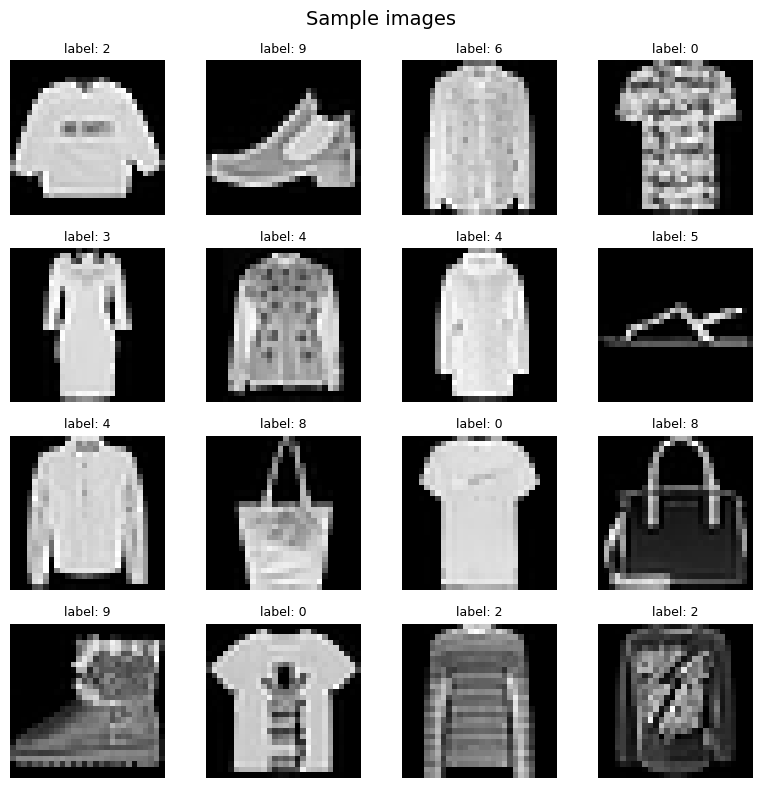

In [195]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle("Sample images", fontsize=14)
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"label: {df.iloc[i, 0]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


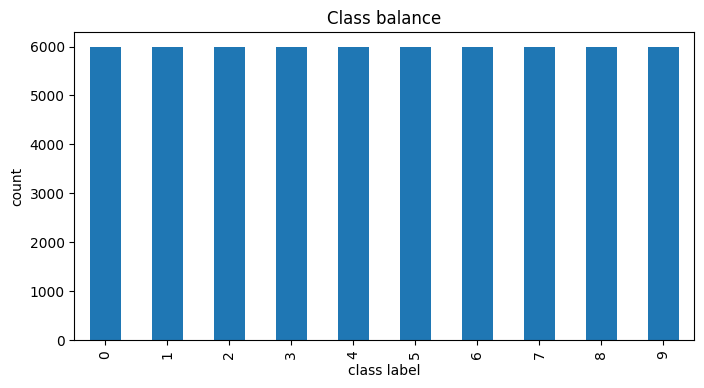

label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [196]:
class_counts = df.iloc[:, 0].value_counts().sort_index()
class_counts.plot(kind="bar", figsize=(8, 4), title="Class balance")
plt.xlabel("class label")
plt.ylabel("count")
plt.show()
print(class_counts)


##  Data Preprocessing


In [197]:
X = df.iloc[:, 1:].values.astype(np.float32)
y = df.iloc[:, 0].values.astype(np.int64)

X = X / 255.0

print(f"X shape: {X.shape}, y shape: {y.shape}")
print(f"X range after scaling: [{X.min():.2f}, {X.max():.2f}]")


X shape: (60000, 784), y shape: (60000,)
X range after scaling: [0.00, 1.00]


##  Train / Validation / Test Split


In [198]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=cfg.test_size, random_state=cfg.seed, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=cfg.seed, stratify=y_temp
)

print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")


Train: 38400 | Val: 9600 | Test: 12000


##  Dataset Class


In [199]:
class TabularDataset(Dataset):
    # Wraps NumPy feature/label arrays as a PyTorch Dataset.

    def __init__(self, features: np.ndarray, labels: np.ndarray):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self) -> int:
        return len(self.features)

    def __getitem__(self, index: int):
        return self.features[index], self.labels[index]


train_dataset = TabularDataset(X_train, y_train)
val_dataset = TabularDataset(X_val, y_val)
test_dataset = TabularDataset(X_test, y_test)

print(f"len(train_dataset) = {len(train_dataset)}")
sample_x, sample_y = train_dataset[0]
print(f"sample feature shape: {sample_x.shape}, sample label: {sample_y.item()}")


len(train_dataset) = 38400
sample feature shape: torch.Size([784]), sample label: 6


## DataLoader


In [200]:
train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=cfg.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=cfg.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print(f"Batches per epoch (train): {len(train_loader)}")


Batches per epoch (train): 600


## Build the Model


In [201]:
class ANN(nn.Module):
    def __init__(
        self,
        input_dim: int,
        num_classes: int,
        num_hidden_layers: int,
        neurons_per_layer: int,
        dropout_rate: float,
    ):
        super().__init__()

        layers = []
        current_dim = input_dim
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(current_dim, neurons_per_layer))
            layers.append(nn.BatchNorm1d(neurons_per_layer))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            current_dim = neurons_per_layer

        layers.append(nn.Linear(current_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


model = ANN(
    input_dim=cfg.input_dim,
    num_classes=cfg.num_classes,
    num_hidden_layers=cfg.num_hidden_layers,
    neurons_per_layer=cfg.neurons_per_layer,
    dropout_rate=cfg.dropout_rate,
).to(device)

print(model)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params:,}")


ANN(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 118,794


##  Weight Initialization


In [202]:
def kaiming_init(module: nn.Module) -> None:
    if isinstance(module, nn.Linear):
        nn.init.kaiming_normal_(module.weight, nonlinearity="relu")
        nn.init.zeros_(module.bias)


model.apply(kaiming_init)
print("Weights re-initialized with Kaiming (He) initialization.")


Weights re-initialized with Kaiming (He) initialization.


## Loss Function


In [203]:
criterion = nn.CrossEntropyLoss()


## Optimizer


In [204]:
def build_optimizer(
    model: nn.Module,
    name: str,
    lr: float,
    weight_decay: float,
) -> optim.Optimizer:
    """
    Build and return the requested optimizer.

    Supported Optimizers:
        - Adam
        - AdamW
        - SGD (with Momentum)
        - RMSprop
    """

    if name == "Adam":
        return optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

    elif name == "AdamW":
        return optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

    elif name == "SGD":
        return optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay,
        )

    elif name == "RMSprop":
        return optim.RMSprop(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

    else:
        raise ValueError(
            f"Unsupported optimizer '{name}'. "
            "Choose from: Adam, AdamW, SGD, RMSprop."
        )


optimizer = build_optimizer(
    model=model,
    name=cfg.optimizer_name,
    lr=cfg.learning_rate,
    weight_decay=cfg.weight_decay,
)

print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


## Learning Rate Scheduler


In [205]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)


## Training & Validation Loop


In [206]:
# Stage 1: fully explicit, single epoch shown for inspection

model.train()  # enables Dropout, uses batch statistics in BatchNorm
running_loss = 0.0

for batch_features, batch_labels in train_loader:
    batch_features = batch_features.to(device)
    batch_labels = batch_labels.to(device)

    optimizer.zero_grad()

    outputs = model(batch_features)
    loss = criterion(outputs, batch_labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item() * batch_features.size(0)

train_loss = running_loss / len(train_dataset)
print(f"Stage-1 demo — one training epoch, train loss: {train_loss:.4f}")

# Validation: same forward pass, no gradient updates
model.eval()  # disables Dropout, uses running statistics in BatchNorm
val_loss = 0.0
with torch.no_grad():
    for batch_features, batch_labels in val_loader:
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)
        outputs = model(batch_features)
        loss = criterion(outputs, batch_labels)
        val_loss += loss.item() * batch_features.size(0)

val_loss = val_loss / len(val_dataset)
print(f"Stage-1 demo — validation loss: {val_loss:.4f}")


Stage-1 demo — one training epoch, train loss: 0.6591
Stage-1 demo — validation loss: 0.4253


###  refactor into reusable functions


In [207]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device,
    scaler: GradScaler = None,
) -> float:
    model.train()
    running_loss = 0.0

    for batch_features, batch_labels in loader:
        batch_features = batch_features.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        if scaler is not None:
            # Mixed precision path — see Section 22 for why this differs
            with autocast(device_type=device.type):
                outputs = model(batch_features)
                loss = criterion(outputs, batch_labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * batch_features.size(0)

    return running_loss / len(loader.dataset)


@torch.no_grad()
def validate(
    model: nn.Module, loader: DataLoader, criterion: nn.Module, device: torch.device
) -> float:
    model.eval()
    running_loss = 0.0

    for batch_features, batch_labels in loader:
        batch_features = batch_features.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)
        outputs = model(batch_features)
        loss = criterion(outputs, batch_labels)
        running_loss += loss.item() * batch_features.size(0)

    return running_loss / len(loader.dataset)


##  Metrics


In [208]:
@torch.no_grad()
def get_predictions(model: nn.Module, loader: DataLoader, device: torch.device):
    model.eval()
    all_preds, all_labels = [], []

    for batch_features, batch_labels in loader:
        batch_features = batch_features.to(device)
        outputs = model(batch_features)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(batch_labels.numpy())

    return np.array(all_preds), np.array(all_labels)


def compute_metrics(preds: np.ndarray, labels: np.ndarray) -> dict:
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision_macro": precision_score(labels, preds, average="macro", zero_division=0),
        "recall_macro": recall_score(labels, preds, average="macro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    }


##  Early Stopping


In [209]:
class EarlyStopping:
    def __init__(self, patience: int = 5, min_delta: float = 0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss: float) -> bool:
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop


## Model Checkpointing


In [210]:
def save_checkpoint(model: nn.Module, path: str) -> None:
    torch.save(model.state_dict(), path)


def load_checkpoint(model: nn.Module, path: str, device: torch.device) -> nn.Module:
    model.load_state_dict(torch.load(path, map_location=device))
    return model


##  Mixed Precision Training


In [211]:
use_amp = cfg.use_amp and device.type == "cuda"
scaler = GradScaler(device=device.type) if use_amp else None
print(f"Mixed precision enabled: {use_amp}")


Mixed precision enabled: True


## Putting it together: a full training run


In [212]:
def run_training(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    scheduler,
    device: torch.device,
    epochs: int,
    patience: int,
    checkpoint_path: str,
    use_amp: bool = False,
    trial: "optuna.trial.Trial | None" = None,
) -> dict:
    scaler = GradScaler(device=device.type) if use_amp else None
    early_stopper = EarlyStopping(patience=patience)
    history = {"train_loss": [], "val_loss": []}
    start_time = time.time()

    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device, scaler)
        val_loss = validate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if scheduler is not None:
            scheduler.step(val_loss)

        if val_loss < early_stopper.best_loss:
            save_checkpoint(model, checkpoint_path)

        print(f"Epoch {epoch + 1}/{epochs} | train_loss: {train_loss:.4f} | val_loss: {val_loss:.4f}")

        # Optuna pruning: stop unpromising trials early instead of running
        # them to completion — see Section 23.
        if trial is not None:
            trial.report(val_loss, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if early_stopper.step(val_loss):
            print(f"Early stopping triggered at epoch {epoch + 1}.")
            break

    load_checkpoint(model, checkpoint_path, device)
    history["training_time_seconds"] = time.time() - start_time
    return history


### Refactor: one place to build a model/optimizer/scheduler, one place to build loaders


In [213]:
def build_model_optimizer_scheduler(
    num_hidden_layers: int,
    neurons_per_layer: int,
    dropout_rate: float,
    optimizer_name: str,
    learning_rate: float,
    weight_decay: float,
):
    """Builds a FRESH model + optimizer + scheduler from scratch.

    Used identically by the baseline run, every Optuna trial, and the final
    retrain, so none of them can accidentally diverge in how they're built.
    """
    model = ANN(
        input_dim=cfg.input_dim,
        num_classes=cfg.num_classes,
        num_hidden_layers=num_hidden_layers,
        neurons_per_layer=neurons_per_layer,
        dropout_rate=dropout_rate,
    ).to(device)
    model.apply(kaiming_init)

    optimizer = build_optimizer(model, optimizer_name, learning_rate, weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    return model, optimizer, scheduler


def make_loaders(batch_size: int):
    """Builds train/val DataLoaders for a given batch size.

    Reused by the baseline (cfg.batch_size), every Optuna trial (its own
    suggested batch_size), and the final retrain (best_params["batch_size"]).
    """
    loader_train = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        pin_memory=(device.type == "cuda"),
    )
    loader_val = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False,
        pin_memory=(device.type == "cuda"),
    )
    return loader_train, loader_val


## Phase 1 — Baseline: train once, evaluate thoroughly


Epoch 1/20 | train_loss: 0.6563 | val_loss: 0.4354
Epoch 2/20 | train_loss: 0.4744 | val_loss: 0.4125
Epoch 3/20 | train_loss: 0.4297 | val_loss: 0.3741
Epoch 4/20 | train_loss: 0.3998 | val_loss: 0.3565
Epoch 5/20 | train_loss: 0.3806 | val_loss: 0.3621
Epoch 6/20 | train_loss: 0.3639 | val_loss: 0.3398
Epoch 7/20 | train_loss: 0.3506 | val_loss: 0.3242
Epoch 8/20 | train_loss: 0.3435 | val_loss: 0.3339
Epoch 9/20 | train_loss: 0.3308 | val_loss: 0.3211
Epoch 10/20 | train_loss: 0.3194 | val_loss: 0.3263
Epoch 11/20 | train_loss: 0.3146 | val_loss: 0.3144
Epoch 12/20 | train_loss: 0.3080 | val_loss: 0.3170
Epoch 13/20 | train_loss: 0.3016 | val_loss: 0.3231
Epoch 14/20 | train_loss: 0.2901 | val_loss: 0.3221
Epoch 15/20 | train_loss: 0.2657 | val_loss: 0.3033
Epoch 16/20 | train_loss: 0.2603 | val_loss: 0.3023
Epoch 17/20 | train_loss: 0.2546 | val_loss: 0.3018
Epoch 18/20 | train_loss: 0.2484 | val_loss: 0.3194
Epoch 19/20 | train_loss: 0.2494 | val_loss: 0.3102
Epoch 20/20 | train_l

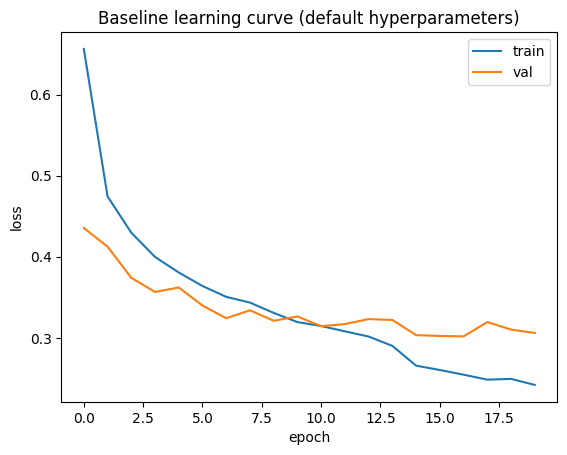

In [214]:
set_seed(cfg.seed)

baseline_model, baseline_optimizer, baseline_scheduler = build_model_optimizer_scheduler(
    num_hidden_layers=cfg.num_hidden_layers,
    neurons_per_layer=cfg.neurons_per_layer,
    dropout_rate=cfg.dropout_rate,
    optimizer_name=cfg.optimizer_name,
    learning_rate=cfg.learning_rate,
    weight_decay=cfg.weight_decay,
)

baseline_history = run_training(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=baseline_optimizer,
    scheduler=baseline_scheduler,
    device=device,
    epochs=cfg.epochs,
    patience=cfg.patience,
    checkpoint_path="baseline_model.pt",
    use_amp=use_amp,
)

plt.plot(baseline_history["train_loss"], label="train")
plt.plot(baseline_history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("Baseline learning curve (default hyperparameters)")
plt.show()


Baseline results (train + validation only — test set untouched):
  training loss (final epoch):   0.2419
  validation loss (final epoch): 0.3060
  training accuracy:             0.9337
  validation accuracy:           0.8942
  validation precision (macro):  0.8944
  validation recall (macro):     0.8942
  validation F1 (macro):         0.8938
  parameters:                    118,794
  training time:                 58.1s


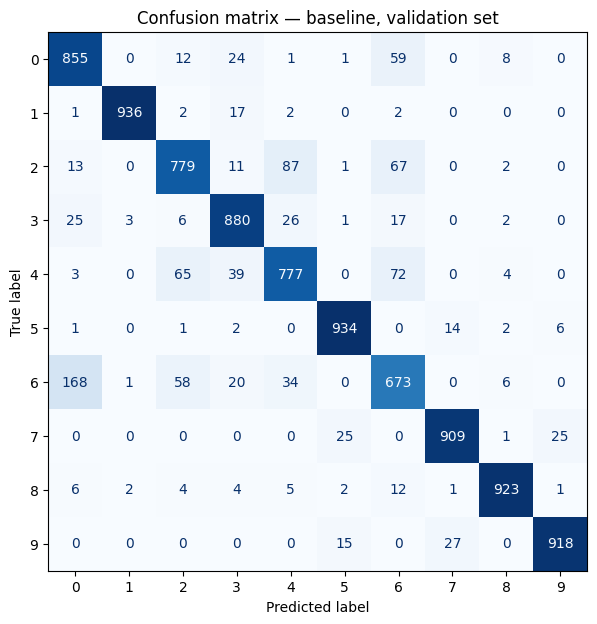

In [215]:
# Evaluate the baseline on train and validation only — test stays sealed.
baseline_train_preds, baseline_train_labels = get_predictions(baseline_model, train_loader, device)
baseline_train_metrics = compute_metrics(baseline_train_preds, baseline_train_labels)

baseline_val_preds, baseline_val_labels = get_predictions(baseline_model, val_loader, device)
baseline_val_metrics = compute_metrics(baseline_val_preds, baseline_val_labels)

baseline_num_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
baseline_train_time = baseline_history["training_time_seconds"]

print("Baseline results (train + validation only — test set untouched):")
print(f"  training loss (final epoch):   {baseline_history['train_loss'][-1]:.4f}")
print(f"  validation loss (final epoch): {baseline_history['val_loss'][-1]:.4f}")
print(f"  training accuracy:             {baseline_train_metrics['accuracy']:.4f}")
print(f"  validation accuracy:           {baseline_val_metrics['accuracy']:.4f}")
print(f"  validation precision (macro):  {baseline_val_metrics['precision_macro']:.4f}")
print(f"  validation recall (macro):     {baseline_val_metrics['recall_macro']:.4f}")
print(f"  validation F1 (macro):         {baseline_val_metrics['f1_macro']:.4f}")
print(f"  parameters:                    {baseline_num_params:,}")
print(f"  training time:                 {baseline_train_time:.1f}s")

cm = confusion_matrix(baseline_val_labels, baseline_val_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix — baseline, validation set")
plt.show()


### Reading the gap between training and validation accuracy


## Phase 2 — Decision: is the baseline worth tuning further?


In [216]:
MIN_ACCEPTABLE_TRAIN_ACC = 0.5  # sanity floor, well above 1/num_classes chance level

train_acc = baseline_train_metrics["accuracy"]
val_acc = baseline_val_metrics["accuracy"]
gap = train_acc - val_acc

if train_acc < MIN_ACCEPTABLE_TRAIN_ACC:
    print(
        f"Training accuracy ({train_acc:.4f}) is close to chance level. "
        "This points to a pipeline bug (data, labels, or model wiring) rather than "
        "a hyperparameter problem — debug that before running Optuna."
    )
else:
    print(f"Training accuracy ({train_acc:.4f}) is satisfactory — proceeding to hyperparameter tuning.")
    if gap > 0.15:
        print(f"Train/val gap is large ({gap:.4f}) — likely overfitting; tuning will search regularization.")
    elif val_acc < 0.7:
        print(f"Val accuracy ({val_acc:.4f}) is still modest — tuning will search capacity and learning rate.")
    else:
        print("Baseline already generalizes reasonably — tuning here is about optimizing further, not fixing a problem.")


Training accuracy (0.9337) is satisfactory — proceeding to hyperparameter tuning.
Baseline already generalizes reasonably — tuning here is about optimizing further, not fixing a problem.


## Hyperparameter Tuning with Optuna


In [ ]:
def objective(trial: optuna.trial.Trial) -> float:
    # Suggest hyperparameters for this trial
    num_hidden_layers = trial.suggest_int("num_hidden_layers", 1, 4)
    neurons_per_layer = trial.suggest_int("neurons_per_layer", 32, 256, step=32)
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5, step=0.1)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-1, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam","AdamW", "SGD", "RMSprop"])

    set_seed(cfg.seed)  # reproducibility across trials, see note above

    trial_train_loader, trial_val_loader = make_loaders(batch_size)

    trial_model, trial_optimizer, trial_scheduler = build_model_optimizer_scheduler(
        num_hidden_layers=num_hidden_layers,
        neurons_per_layer=neurons_per_layer,
        dropout_rate=dropout_rate,
        optimizer_name=optimizer_name,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
    )

    history = run_training(
        model=trial_model,
        train_loader=trial_train_loader,
        val_loader=trial_val_loader,
        criterion=criterion,
        optimizer=trial_optimizer,
        scheduler=trial_scheduler,
        device=device,
        epochs=15,               # kept short per trial; pruning cuts weak ones sooner
        patience=4,
        checkpoint_path=f"trial_{trial.number}.pt",
        use_amp=use_amp,
        trial=trial,
    )

    return min(history["val_loss"])


study = optuna.create_study(
    direction="minimize",
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
)
study.optimize(objective, n_trials=20)

print(f"Best val_loss: {study.best_value:.4f}")
print(f"Best params: {study.best_params}")


[I 2026-08-01 07:53:50,971] A new study created in memory with name: no-name-0805e6e6-8064-4192-b85a-0795ff328f2f


Epoch 1/15 | train_loss: 0.5359 | val_loss: 0.4271
Epoch 2/15 | train_loss: 0.4082 | val_loss: 0.3658
Epoch 3/15 | train_loss: 0.3650 | val_loss: 0.3535
Epoch 4/15 | train_loss: 0.3393 | val_loss: 0.3528
Epoch 5/15 | train_loss: 0.3166 | val_loss: 0.3523
Epoch 6/15 | train_loss: 0.2987 | val_loss: 0.3381
Epoch 7/15 | train_loss: 0.2893 | val_loss: 0.3246
Epoch 8/15 | train_loss: 0.2743 | val_loss: 0.3300
Epoch 9/15 | train_loss: 0.2632 | val_loss: 0.3292
Epoch 10/15 | train_loss: 0.2549 | val_loss: 0.3257
Epoch 11/15 | train_loss: 0.2173 | val_loss: 0.3150
Epoch 12/15 | train_loss: 0.2069 | val_loss: 0.3100
Epoch 13/15 | train_loss: 0.1978 | val_loss: 0.3098
Epoch 14/15 | train_loss: 0.1945 | val_loss: 0.3277


[I 2026-08-01 07:54:17,522] Trial 0 finished with value: 0.3097995416820049 and parameters: {'num_hidden_layers': 1, 'neurons_per_layer': 256, 'dropout_rate': 0.2, 'batch_size': 64, 'learning_rate': 0.04615182408593697, 'weight_decay': 2.0851341057684696e-05, 'optimizer': 'SGD'}. Best is trial 0 with value: 0.3097995416820049.


Epoch 15/15 | train_loss: 0.1882 | val_loss: 0.3292
Epoch 1/15 | train_loss: 0.6946 | val_loss: 0.5841
Epoch 2/15 | train_loss: 0.6695 | val_loss: 0.5630
Epoch 3/15 | train_loss: 0.6673 | val_loss: 0.6021
Epoch 4/15 | train_loss: 0.6714 | val_loss: 0.7828
Epoch 5/15 | train_loss: 0.6633 | val_loss: 0.6129


[I 2026-08-01 07:54:33,086] Trial 1 finished with value: 0.5629513738552729 and parameters: {'num_hidden_layers': 2, 'neurons_per_layer': 160, 'dropout_rate': 0.1, 'batch_size': 64, 'learning_rate': 0.049150411490126944, 'weight_decay': 0.0001399762012733269, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.3097995416820049.


...

Epoch 7/15 | train_loss: 0.3800 | val_loss: 0.3492
Epoch 1/15 | train_loss: 0.6336 | val_loss: 0.4628
Epoch 2/15 | train_loss: 0.5225 | val_loss: 0.4339
Epoch 3/15 | train_loss: 0.5045 | val_loss: 0.4201


[I 2026-08-01 08:02:37,054] Trial 18 pruned. 


Epoch 4/15 | train_loss: 0.4918 | val_loss: 0.4315
Epoch 1/15 | train_loss: 0.8439 | val_loss: 0.5686
Epoch 2/15 | train_loss: 0.6912 | val_loss: 0.5145
Epoch 3/15 | train_loss: 0.6785 | val_loss: 0.4550


[I 2026-08-01 08:02:53,563] Trial 19 pruned. 


Epoch 4/15 | train_loss: 0.6687 | val_loss: 0.4681
Best val_loss: 0.3017
Best params: {'num_hidden_layers': 2, 'neurons_per_layer': 256, 'dropout_rate': 0.30000000000000004, 'batch_size': 32, 'learning_rate': 0.0003292682977088245, 'weight_decay': 1.0956533354806505e-06, 'optimizer': 'RMSprop'}


## Phase 4 — Retrain the Best Model


Epoch 1/20 | train_loss: 0.6028 | val_loss: 0.4080
Epoch 2/20 | train_loss: 0.4654 | val_loss: 0.3701
Epoch 3/20 | train_loss: 0.4212 | val_loss: 0.3520
Epoch 4/20 | train_loss: 0.3922 | val_loss: 0.3426
Epoch 5/20 | train_loss: 0.3715 | val_loss: 0.3435
Epoch 6/20 | train_loss: 0.3564 | val_loss: 0.3285
Epoch 7/20 | train_loss: 0.3416 | val_loss: 0.3254
Epoch 8/20 | train_loss: 0.3288 | val_loss: 0.3558
Epoch 9/20 | train_loss: 0.3203 | val_loss: 0.3140
Epoch 10/20 | train_loss: 0.3092 | val_loss: 0.3148
Epoch 11/20 | train_loss: 0.3015 | val_loss: 0.3082
Epoch 12/20 | train_loss: 0.2930 | val_loss: 0.3111
Epoch 13/20 | train_loss: 0.2861 | val_loss: 0.3161
Epoch 14/20 | train_loss: 0.2811 | val_loss: 0.3017
Epoch 15/20 | train_loss: 0.2694 | val_loss: 0.3120
Epoch 16/20 | train_loss: 0.2657 | val_loss: 0.3177
Epoch 17/20 | train_loss: 0.2629 | val_loss: 0.3092
Epoch 18/20 | train_loss: 0.2403 | val_loss: 0.2958
Epoch 19/20 | train_loss: 0.2277 | val_loss: 0.3015
Epoch 20/20 | train_l

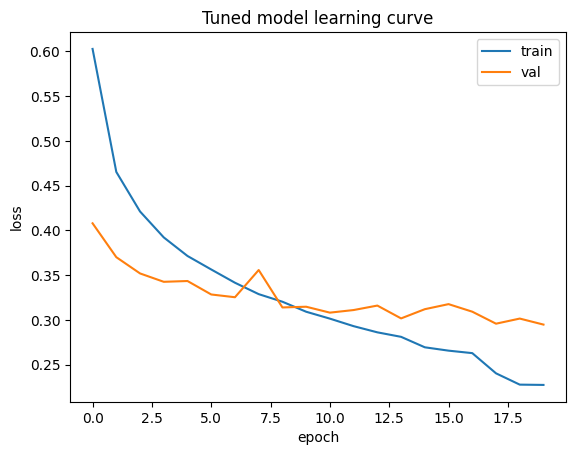

In [218]:
best_params = study.best_params
set_seed(cfg.seed)

final_train_loader, final_val_loader = make_loaders(best_params["batch_size"])

final_model, final_optimizer, final_scheduler = build_model_optimizer_scheduler(
    num_hidden_layers=best_params["num_hidden_layers"],
    neurons_per_layer=best_params["neurons_per_layer"],
    dropout_rate=best_params["dropout_rate"],
    optimizer_name=best_params["optimizer"],
    learning_rate=best_params["learning_rate"],
    weight_decay=best_params["weight_decay"],
)

history = run_training(
    model=final_model,
    train_loader=final_train_loader,
    val_loader=final_val_loader,
    criterion=criterion,
    optimizer=final_optimizer,
    scheduler=final_scheduler,
    device=device,
    epochs=cfg.epochs,
    patience=cfg.patience,
    checkpoint_path=cfg.checkpoint_path,
    use_amp=use_amp,
)

plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("Tuned model learning curve")
plt.show()


In [219]:
final_train_preds, final_train_labels = get_predictions(final_model, final_train_loader, device)
final_train_metrics = compute_metrics(final_train_preds, final_train_labels)

final_val_preds, final_val_labels = get_predictions(final_model, final_val_loader, device)
final_val_metrics = compute_metrics(final_val_preds, final_val_labels)

final_num_params = sum(p.numel() for p in final_model.parameters() if p.requires_grad)
final_train_time = history["training_time_seconds"]


##  Final Evaluation — the test set, exactly once


Final test-set metrics (tuned model, evaluated once):
  accuracy: 0.8937
  precision_macro: 0.8953
  recall_macro: 0.8937
  f1_macro: 0.8923


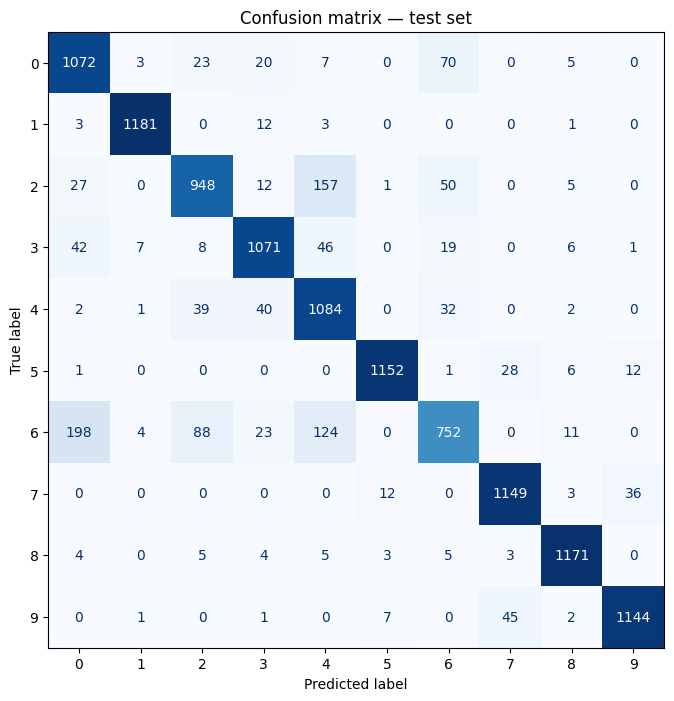

In [220]:
test_preds, test_labels = get_predictions(final_model, test_loader, device)
test_metrics = compute_metrics(test_preds, test_labels)

print("Final test-set metrics (tuned model, evaluated once):")
for name, value in test_metrics.items():
    print(f"  {name}: {value:.4f}")

cm = confusion_matrix(test_labels, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix — test set")
plt.show()


## Phase 5 — Baseline vs. Tuned: the full comparison


In [221]:
comparison = pd.DataFrame(
    {
        "baseline": {
            "train_accuracy": baseline_train_metrics["accuracy"],
            "val_accuracy": baseline_val_metrics["accuracy"],
            "test_accuracy": None,  # test set intentionally not evaluated for baseline
            "train_loss (final epoch)": baseline_history["train_loss"][-1],
            "val_loss (final epoch)": baseline_history["val_loss"][-1],
            "val_precision_macro": baseline_val_metrics["precision_macro"],
            "val_recall_macro": baseline_val_metrics["recall_macro"],
            "val_f1_macro": baseline_val_metrics["f1_macro"],
            "num_parameters": baseline_num_params,
            "training_time_s": round(baseline_train_time, 1),
        },
        "tuned": {
            "train_accuracy": final_train_metrics["accuracy"],
            "val_accuracy": final_val_metrics["accuracy"],
            "test_accuracy": test_metrics["accuracy"],
            "train_loss (final epoch)": history["train_loss"][-1],
            "val_loss (final epoch)": history["val_loss"][-1],
            "val_precision_macro": final_val_metrics["precision_macro"],
            "val_recall_macro": final_val_metrics["recall_macro"],
            "val_f1_macro": final_val_metrics["f1_macro"],
            "num_parameters": final_num_params,
            "training_time_s": round(final_train_time, 1),
        },
    }
)

print(comparison)
print("\nBest hyperparameters found by Optuna:")
print(json.dumps(best_params, indent=2))


                               baseline          tuned
train_accuracy                 0.933750       0.943125
val_accuracy                   0.894167       0.896458
test_accuracy                       NaN       0.893667
train_loss (final epoch)       0.241948       0.227391
val_loss (final epoch)         0.306046       0.294806
val_precision_macro            0.894382       0.897980
val_recall_macro               0.894167       0.896458
val_f1_macro                   0.893846       0.895454
num_parameters            118794.000000  270346.000000
training_time_s               58.100000      84.600000

Best hyperparameters found by Optuna:
{
  "num_hidden_layers": 2,
  "neurons_per_layer": 256,
  "dropout_rate": 0.30000000000000004,
  "batch_size": 32,
  "learning_rate": 0.0003292682977088245,
  "weight_decay": 1.0956533354806505e-06,
  "optimizer": "RMSprop"
}


### Interpreting the table


##  Save the Model


In [222]:
artifact_dir = Path("model_artifact")
artifact_dir.mkdir(exist_ok=True)

torch.save(final_model.state_dict(), artifact_dir / "weights.pt")

with open(artifact_dir / "config.json", "w") as f:
    json.dump(asdict(cfg), f, indent=2)

with open(artifact_dir / "best_hyperparameters.json", "w") as f:
    json.dump(best_params, f, indent=2)

print(f"Saved model artifact to: {artifact_dir.resolve()}")


Saved model artifact to: /content/model_artifact


##  Inference


In [223]:
with open(artifact_dir / "best_hyperparameters.json") as f:
    loaded_params = json.load(f)

inference_model = ANN(
    input_dim=cfg.input_dim,
    num_classes=cfg.num_classes,
    num_hidden_layers=loaded_params["num_hidden_layers"],
    neurons_per_layer=loaded_params["neurons_per_layer"],
    dropout_rate=loaded_params["dropout_rate"],
).to(device)
inference_model.load_state_dict(torch.load(artifact_dir / "weights.pt", map_location=device))
inference_model.eval()


@torch.no_grad()
def predict_single(model: nn.Module, pixels: np.ndarray, device: torch.device) -> int:
    # `pixels` is a flat array of 784 raw pixel values in [0, 255].
    x = torch.tensor(pixels / 255.0, dtype=torch.float32).unsqueeze(0).to(device)
    logits = model(x)
    return logits.argmax(dim=1).item()


# Example: predict on the first test-set sample
example_pixels = df.iloc[0, 1:].values.astype(np.float32)
predicted_class = predict_single(inference_model, example_pixels, device)
print(f"Predicted class: {predicted_class} (true label: {df.iloc[0, 0]})")


Predicted class: 2 (true label: 2)


## Summary
